# Robot-Assisted Farming: performance analysis

This notebook compares the operation modes of the multi-agent system using its KPIs.
Every number comes from `experiments.py`: 10 seeds (0–9) × 1000 steps per configuration, on the
default layout with 4 pickers, 2 drones and storage for 10 strawberries per picker. Runs are
deterministic for a given seed, so re-running gives the same results.

**Configurations**

| Configuration | Crops age & regrow | How pickers find crops |
|---|---|---|
| Basic | no | random exploration; drones hover over crops but cannot signal |
| Extended (broadcast) | yes | drones broadcast each crop area to every picker |
| Extended (direct) | yes | drones message the nearest picker with free storage |
| Novel (Contract Net) | yes | drones auction each crop area; pickers bid their estimated cost |

**KPIs**

* **Harvest rate**: picked ÷ (picked + wasted). The share of ripened strawberries that were saved. *Higher is better.*
* **Energy per strawberry**: battery energy used by all robots ÷ strawberries delivered. *Lower is better.*
* **Mean pick latency**: steps between a crop ripening and being picked. *Lower is better.*
* **Messages sent**: communication load (a broadcast counts once). *Lower is cheaper.*
* Delivered, wasted and picker utilisation are also recorded.

In [1]:
import os
import pandas as pd
from IPython.display import Image, display

import experiments as ex

RESULTS = os.path.join("..", "results")
final_path = os.path.join(RESULTS, "final_kpis.csv")
if not os.path.exists(final_path):          # first run: generate the data (takes ~1-2 minutes)
    os.makedirs(RESULTS, exist_ok=True)
    finals, series = ex.run_all(seeds=10, steps=1000)
    finals.to_csv(final_path, index=False)
    series.to_csv(os.path.join(RESULTS, "timeseries.csv"), index=False)

finals = pd.read_csv(final_path)
series = pd.read_csv(os.path.join(RESULTS, "timeseries.csv"))
len(finals), finals["Config"].unique().tolist()

(40,
 ['Basic',
  'Extended (broadcast)',
  'Extended (direct)',
  'Novel (Contract Net)'])

## 1. Summary table (mean and standard deviation over 10 seeds)

In [2]:
order = [c[0] for c in ex.CONFIGS]
summary = finals.groupby("Config")[ex.KPIS].agg(["mean", "std"]).reindex(order).round(2)
summary

Delivered        Wasted        Harvest rate        \
                          mean    std   mean    std         mean   std   
Config                                                                   
Basic                     69.2   3.79    0.0   0.00         1.00  0.00   
Extended (broadcast)     277.8  29.36  215.9  21.26         0.58  0.04   
Extended (direct)        308.3  26.39  199.0  17.40         0.62  0.04   
Novel (Contract Net)     296.0  20.81  202.6  15.48         0.61  0.02   

                     Energy per strawberry       Mean pick latency         \
                                      mean   std              mean    std   
Config                                                                      
Basic                                16.90  5.03            155.26  38.13   
Extended (broadcast)                  6.69  0.72             57.55   5.41   
Extended (direct)                     5.81  0.35             58.28   5.11   
Novel (Contract Net)                  5.87  0.41             58.08   2.46   

                     Picker utilisation       Messages sent         
                                   mean   std          mean    std  
Config                                                              
Basic                              0.92  0.01           0.0   0.00  
Extended (broadcast)               0.90  0.02          99.6   7.86  
Extended (direct)                  0.83  0.04          93.2   8.13  
Novel (Contract Net)               0.79  0.05         847.5  70.48

## 2. KPI comparison

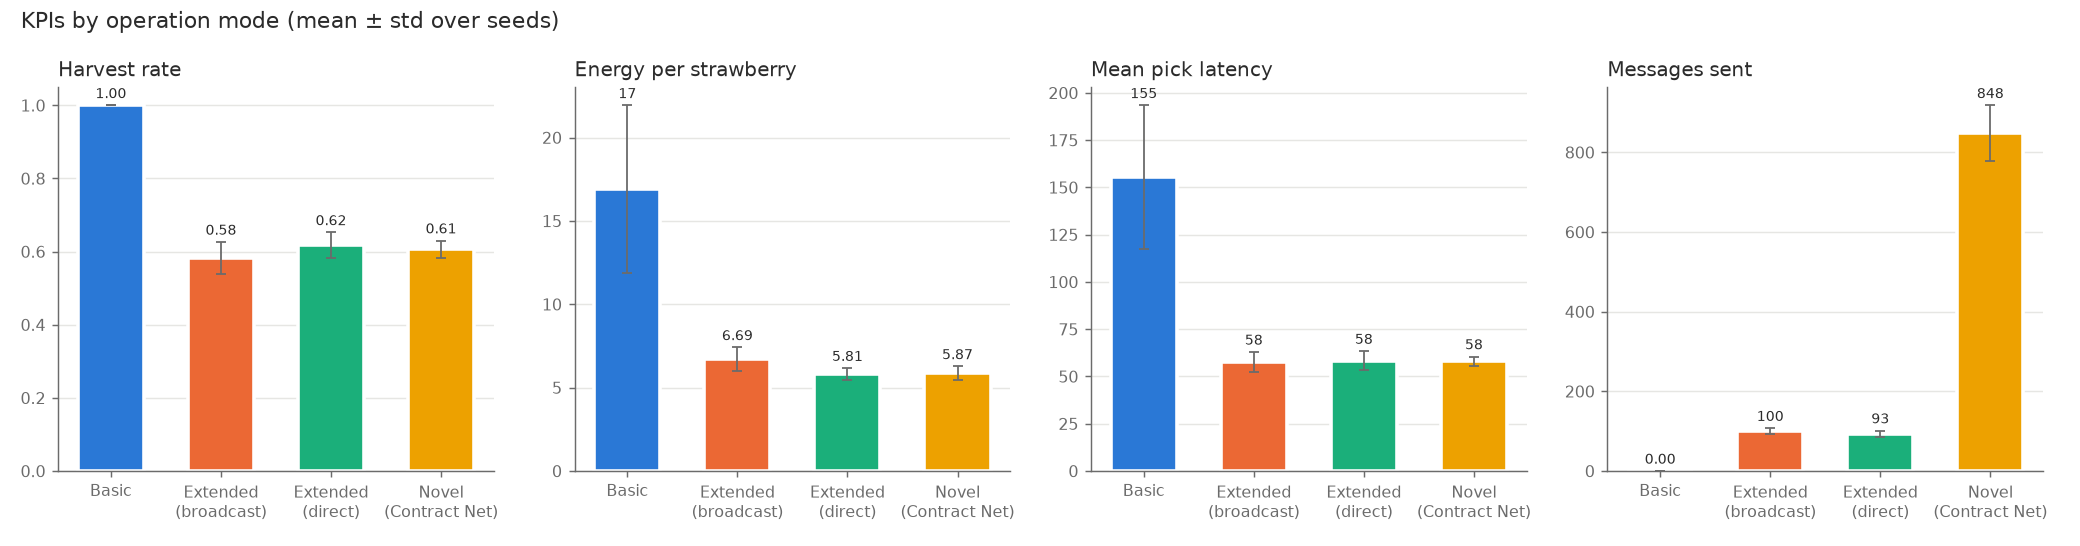

In [3]:
ex.plot_kpi_bars(finals, os.path.join(RESULTS, "kpi_comparison.png"))
display(Image(os.path.join(RESULTS, "kpi_comparison.png")))

## 3. Harvest and waste over time (modes with ageing crops)

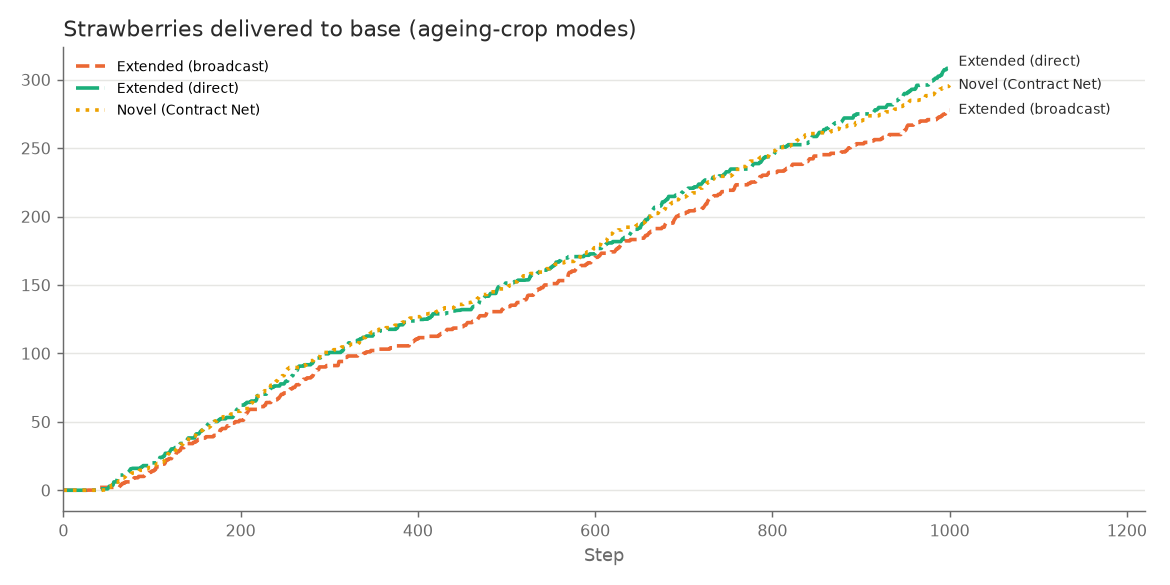

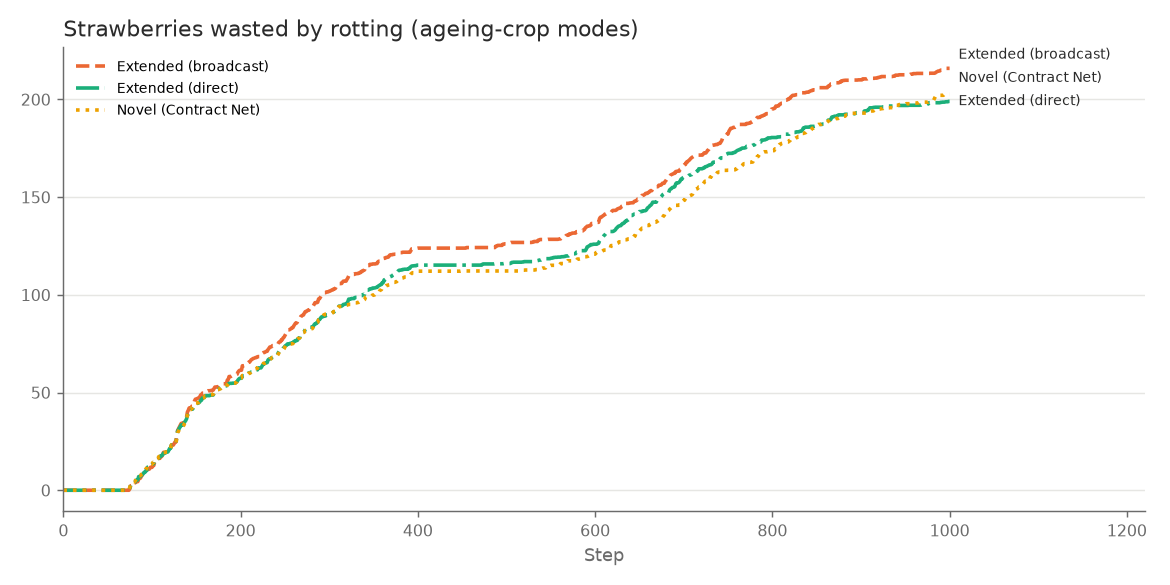

In [4]:
ageing = series[series["Config"] != "Basic"]
ex.plot_over_time(ageing, "Delivered", os.path.join(RESULTS, "delivered_over_time.png"),
                  "Strawberries delivered to base (ageing-crop modes)")
ex.plot_over_time(ageing, "Wasted", os.path.join(RESULTS, "wasted_over_time.png"),
                  "Strawberries wasted by rotting (ageing-crop modes)")
display(Image(os.path.join(RESULTS, "delivered_over_time.png")))
display(Image(os.path.join(RESULTS, "wasted_over_time.png")))

## 4. Sensitivity: how many pickers does the farm need?

Generated with `python experiments.py --sweep` (5 seeds per point).

Pickers,2,4,6,8
Config,,,,
Extended (broadcast),0.424,0.589,0.695,0.743
Extended (direct),0.404,0.614,0.721,0.746
Novel (Contract Net),0.418,0.604,0.682,0.729


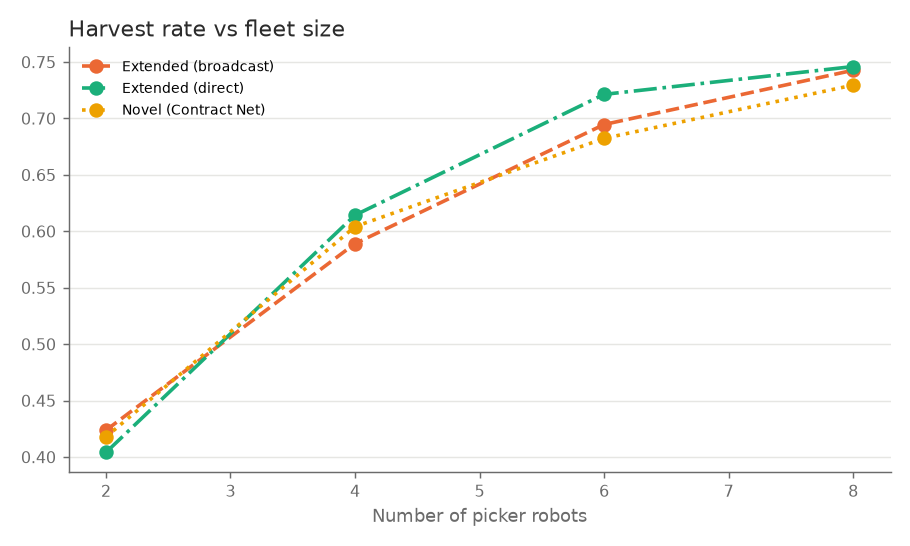

In [5]:
sweep_path = os.path.join(RESULTS, "sweep_pickers.csv")
if os.path.exists(sweep_path):
    sweep = pd.read_csv(sweep_path)
    display(sweep.groupby(["Config", "Pickers"])["Harvest rate"].mean().unstack().round(3))
    display(Image(os.path.join(RESULTS, "sweep_pickers.png")))
else:
    print("Run `python experiments.py --sweep` to generate the sweep.")

## 5. Critical analysis

**Basic vs the communicating modes.** Basic mode reaches a 100% harvest rate, but only because its
crops never age: nothing can rot, and the mission ends once the initial ~70 strawberries are home.
The cost is efficiency. Pickers wander at random, so a strawberry waits about **155 steps** to be
picked (±38 between seeds) and each one costs about **17 energy units**. With drone signals, latency
falls to about **58 steps** and energy per strawberry to **about 6**, roughly a 3× gain on both.
The drones' hovering in Basic mode helps little, because pickers have no way to sense it.

**Broadcast vs direct messaging.** Broadcast sends every picker to every crop area. Several robots
often drive to the same patch and arrive to find it already picked. That wasted travel shows up as
the highest energy per strawberry of the ageing modes (6.69) and the lowest harvest rate (0.58).
Direct messaging gives each area to one robot, raising the harvest rate to **0.62** and lowering
energy to **5.81**, with slightly fewer messages.

**Contract Net (novel mode).** Allocation by auction performs **on par with direct messaging**
(harvest 0.61, energy 5.87), but not better. Its delivery count is the least variable between seeds
(std 20.8 vs 26.4), and latency varies least (std 2.5 vs 5.1), so behaviour is more predictable.
The price is roughly **9× more messages** (≈850 vs ≈93), because every task needs a call for
proposals, one bid per picker and an award. Contract Net earns that overhead when robots differ: in
battery, load or committed work. The bids weigh all three, whereas the direct heuristic only looks
at distance and queue length. On this small, homogeneous farm those factors rarely change the
winner, which explains the tie.

**The dominant factor is fleet size, not coordination.** In every ageing mode, 30–40% of
strawberries rot. The sweep shows the harvest rate climbing from about 0.42 with 2 pickers to about
0.74 with 8, with diminishing returns after 6. Better coordination is worth about 4 percentage
points; two extra pickers are worth about 10. To an operator, the KPI says: buy pickers first, then
use targeted (direct or auction) messaging rather than broadcast.

**Limitations.** The battery and energy figures are abstract units, not watts. Drones are assumed to
know where the pickers are (fleet telemetry) when they choose a recipient for a direct message. The
urgency score stands in for a computer-vision model. Each configuration has only 10 seeds, so
differences of 1–2 points between direct and Contract Net are within one standard deviation and
should not be over-interpreted.

## 6. Advanced options

Each part of the system can be swapped for a more advanced technique (auction format, picker brain,
path finding, drone strategy, network). The data comes from `advanced_experiments.py`: every
configuration runs on the **same 20 seeds** × 1000 steps, so differences come from the configuration,
not from luck (the LLM and XMPP runs use 5 seeds because they are slow).

**How to read the statistics.** One run gives one number, so each configuration is a sample of 20.
Simulation outputs are rarely normal, so the tests are non-parametric:

* **Mann-Whitney U** — is this configuration different from the baseline?
* **Holm correction** — several configurations are compared with one baseline, so the p-values are
  adjusted; otherwise roughly 1 in 20 comparisons would look "significant" by chance.
* **A12 effect size** (Vargha-Delaney) — the chance that a random run of this configuration beats a
  random run of the baseline. 0.5 = no difference; ≥ 0.71 or ≤ 0.29 is a *large* effect.

A result can be significant but small, or large but not significant (too few seeds). Both matter.

In [6]:
ADV = os.path.join(RESULTS, "advanced")
runs = pd.read_csv(os.path.join(ADV, "comparisons.csv"))
stats = pd.read_csv(os.path.join(ADV, "stats.csv"))

def show(experiment, kpis):
    """Mean of each KPI per configuration, plus the harvest-rate test against the baseline."""
    sub = runs[runs["Experiment"] == experiment]
    order = list(dict.fromkeys(sub["Config"]))
    table = sub.groupby("Config")[kpis].mean().reindex(order).round(2)
    test = stats[(stats["Experiment"] == experiment) & (stats["KPI"] == "Harvest rate")].set_index("Config")
    table["p (Holm)"] = test["p_holm"].round(3)
    table["A12"] = test["A12"].round(2)
    table["significant"] = test["significant"]
    display(table)
    display(Image(os.path.join(ADV, f"{experiment}.png")))

### 6.1 Auction formats (WS7)

Contract Net (first-price) against Vickrey (second-price), an English descending-clock auction,
combinatorial bundle bids (CP-SAT winner determination) and a central OR-Tools vehicle-routing
planner. "Strategic" rows let half the pickers shade their bids.

,Harvest rate,Energy per strawberry,Messages sent,Mean regret,Overpayment,Run seconds,p (Holm),A12,significant
Config,,,,,,,,,
Contract Net,0.61,5.90,856.30,0.00,1.00,6.61,NaN,NaN,False
Vickrey,0.61,5.90,856.30,0.00,1.32,6.38,1.000,0.50,False
English,0.63,5.79,5929.85,0.07,1.57,5.28,0.261,0.69,False
Combinatorial,0.61,5.86,658.50,0.00,1.00,8.64,0.957,0.60,False
Central VRP,0.59,6.04,276.60,0.00,0.00,22.94,0.666,0.36,False
"Contract Net, 50% strategic",0.59,5.92,858.65,1.77,1.19,5.79,0.957,0.39,False
"Vickrey, 50% strategic",0.61,5.83,849.20,0.00,1.31,7.39,1.000,0.56,False
"Combinatorial, 50% strategic",0.59,5.96,649.60,0.00,1.17,9.21,0.407,0.33,False


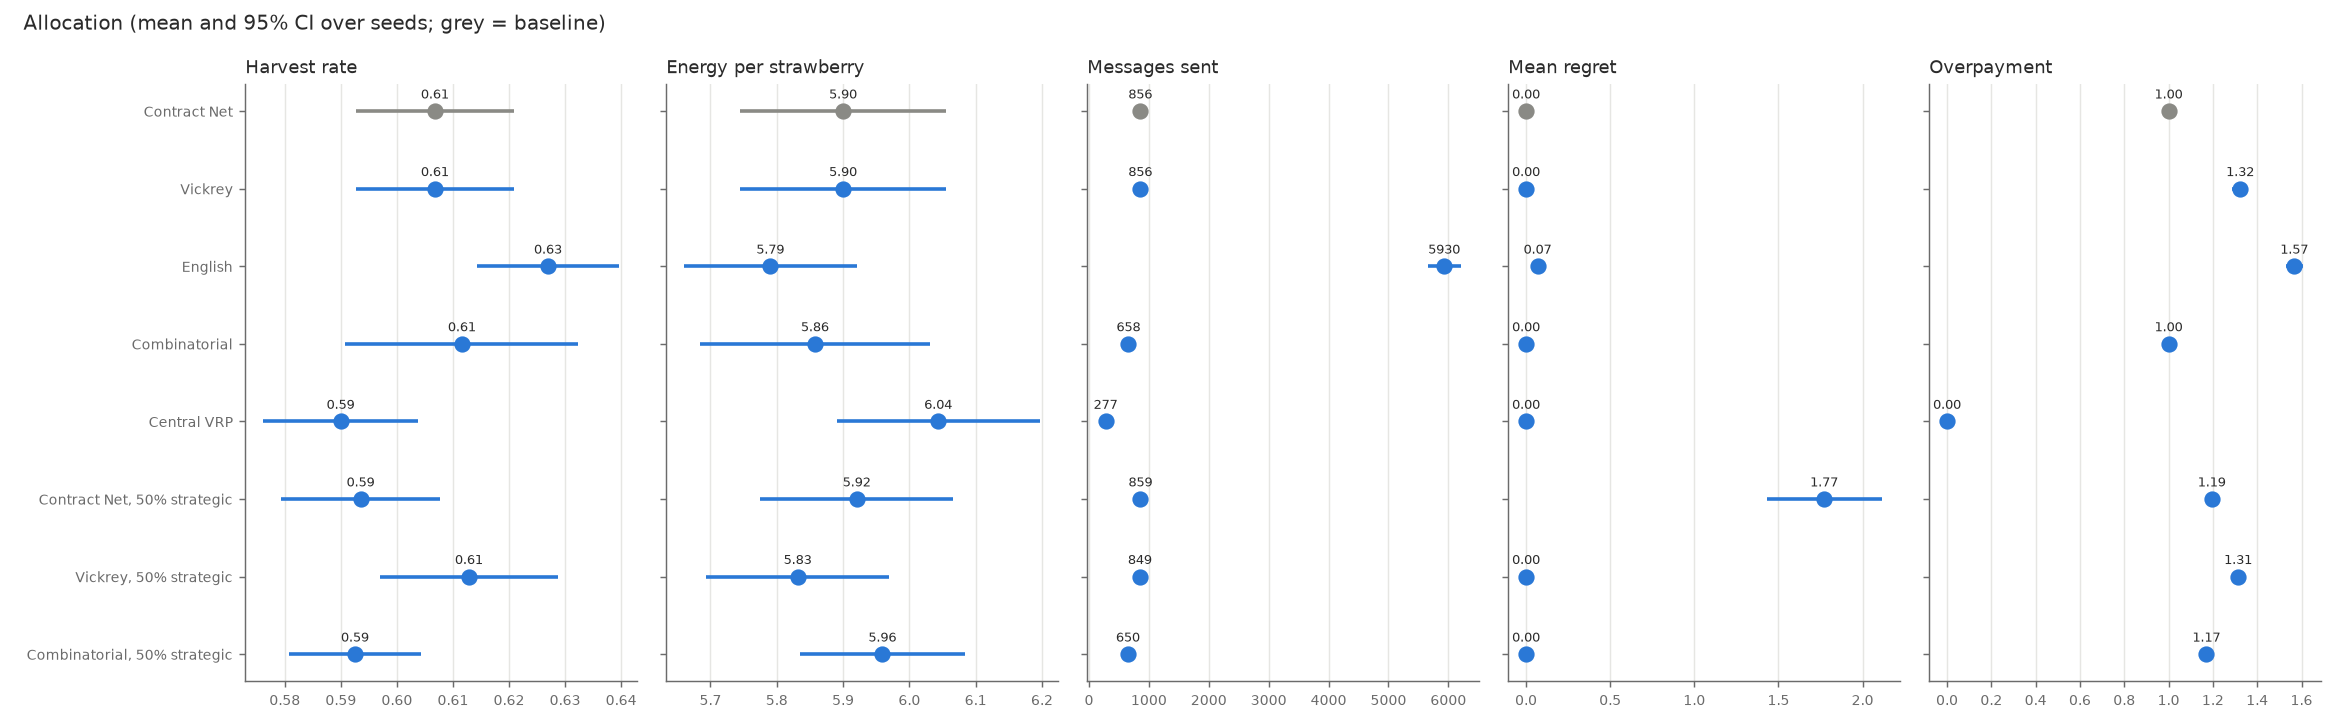

In [7]:
show("allocation", ["Harvest rate", "Energy per strawberry", "Messages sent", "Mean regret", "Overpayment", "Run seconds"])

**Reading it.** With truthful bidders, **Contract Net and Vickrey give identical allocations**: both
award the job to the lowest bid, and only the *price* differs (Vickrey pays the second-lowest).
That is the textbook result, and it is why every KPI except the payments matches. The
difference shows when half the bidders are strategic. In Contract Net, shading bids pays, and the
shaded bids sometimes win jobs another picker could do more cheaply: **mean regret rises from 0
to 1.77**. In Vickrey, bidding your true cost is a dominant strategy, so **regret stays at 0**.
The price of that truthfulness is overpayment: Vickrey pays about 1.3× the winner's cost, against
1.0× for first-price. The **English** auction reaches a
slightly higher harvest (not significant) at **7× the messages**, because every price step is a
round of communication. The **central planner** does not beat the decentralised auctions and is
3–4× slower to run, so for this farm decentralised allocation loses little.

### 6.2 Path finding: independent Dijkstra vs Conflict-Based Search (WS2–3 Activity 3)

,Harvest rate,Blocked steps,Mean pick latency,Run seconds,p (Holm),A12,significant
Config,,,,,,,
Independent,0.62,174.70,58.07,4.72,NaN,NaN,False
Windowed CBS,0.65,7.55,59.33,8.57,0.013,0.73,True


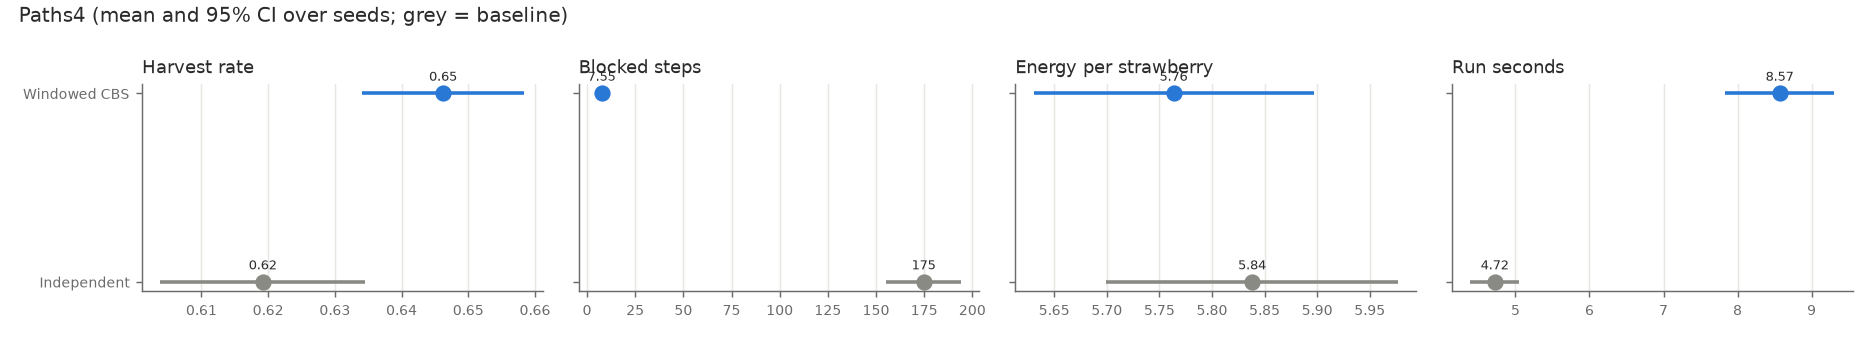

,Harvest rate,Blocked steps,Mean pick latency,Run seconds,p (Holm),A12,significant
Config,,,,,,,
Independent,0.75,444.45,53.35,5.81,NaN,NaN,False
Windowed CBS,0.76,17.45,53.94,10.24,0.86,0.52,False


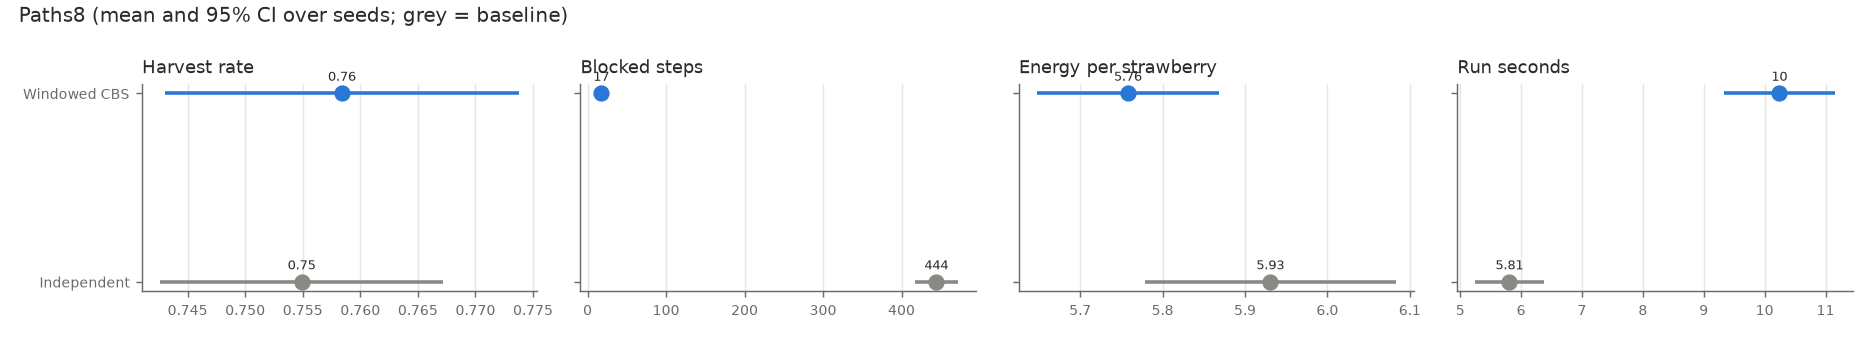

In [8]:
show("paths4", ["Harvest rate", "Blocked steps", "Mean pick latency", "Run seconds"])
show("paths8", ["Harvest rate", "Blocked steps", "Mean pick latency", "Run seconds"])

**Reading it.** Planning all pickers' routes together (CBS) removes almost all blocking: 175 → 8
blocked steps with 4 pickers and 444 → 17 with 8. With 4 pickers this lifts the harvest
significantly (A12 ≈ 0.73, a large effect). With 8 pickers the harvest barely moves even though
blocking collapses: the bottleneck is then the number of ripe crops, not traffic. CBS costs about
twice the computation time.

### 6.3 Drones: random roaming vs the sector game (WS6)

Each drone chooses a farm sector. Two drones in the same sector find fewer new crops each, so this
is a **congestion game**; such games always have a pure Nash equilibrium (Rosenthal, 1973), found
here by best-response dynamics. Fictitious play instead best-responds to the *history* of the
other drones' choices.

,Harvest rate,Mean detection latency,Messages sent,p (Holm),A12,significant
Config,,,,,,
Random roaming,0.62,43.65,95.50,NaN,NaN,False
Nash sectors,0.59,40.40,92.30,0.032,0.28,True
Fictitious play,0.63,40.36,136.95,0.379,0.58,False


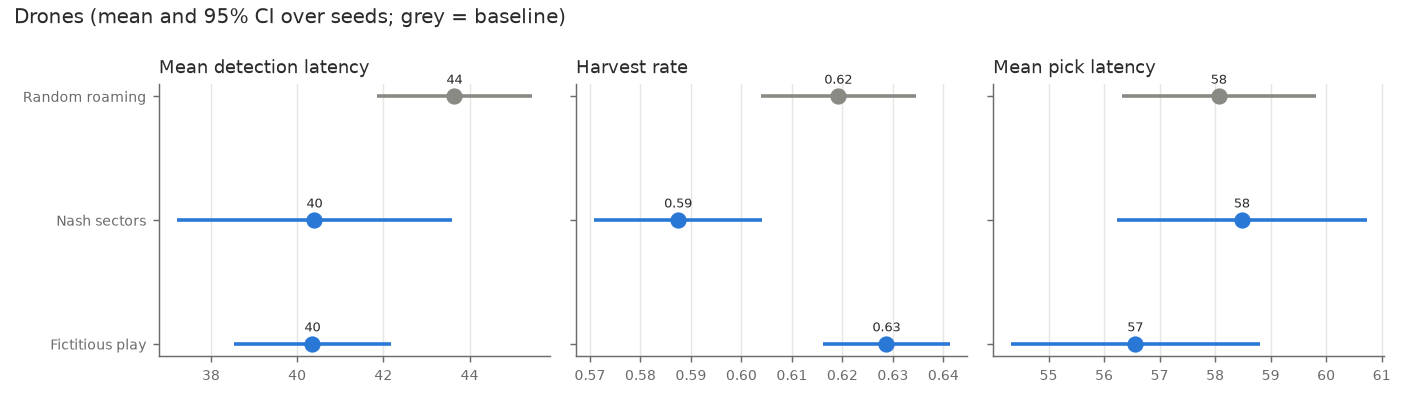

In [9]:
show("drones", ["Harvest rate", "Mean detection latency", "Messages sent"])

**Reading it.** The Nash sector strategy is **significantly worse** than roaming at random. This
is the gap between individual and collective good from WS6: at the equilibrium no drone can do
better by changing sector alone, but the equilibrium sectors are fixed, so crops ripening
elsewhere wait longer to be found. Random roaming covers the whole farm over time. Equilibrium is
a stability concept, not an optimality one.

### 6.4 Unreliable networks

The lossy radio drops each message with a given probability.

,Harvest rate,Messages sent,Mean pick latency,p (Holm),A12,significant
Config,,,,,,
Ideal,0.61,856.30,58.88,NaN,NaN,False
Lossy 10%,0.60,762.50,59.33,0.379,0.42,False
Lossy 30%,0.56,643.40,59.44,0.000,0.12,True
Lossy 50%,0.43,485.35,62.31,0.000,0.00,True
"Extended direct, lossy 30%",0.57,103.75,59.27,0.004,0.21,True


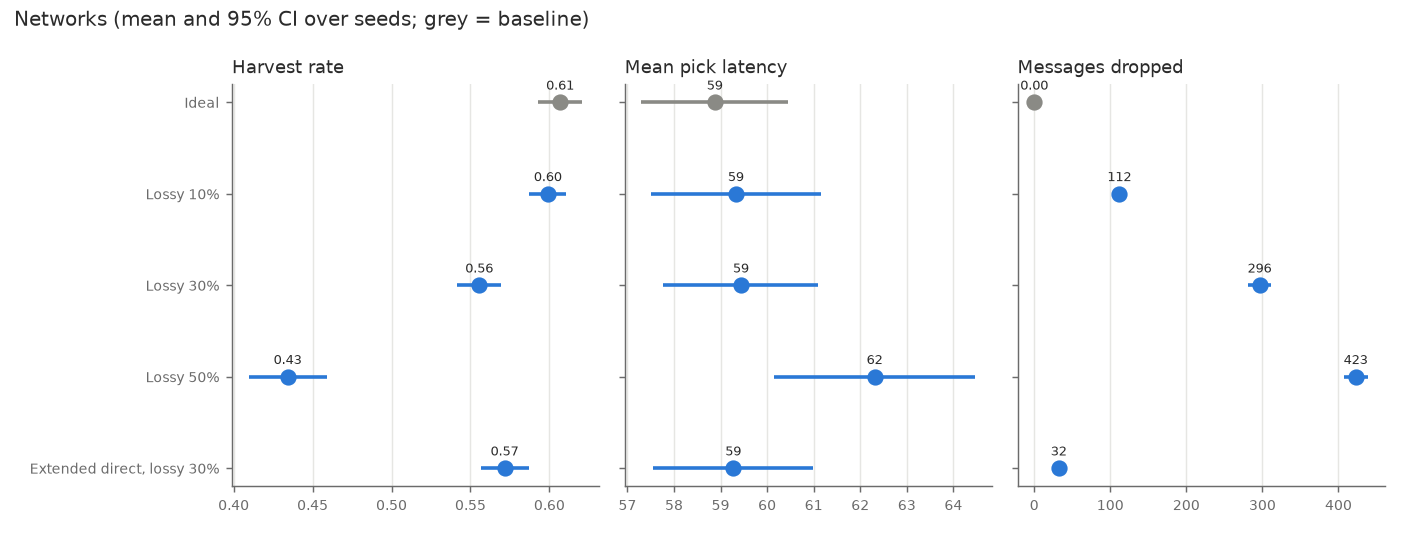

In [10]:
show("networks", ["Harvest rate", "Messages sent", "Mean pick latency"])

**Reading it.** Coordination tolerates 10 % loss with no significant change, then degrades:
significantly worse at 30 % loss and much worse at 50 % (0.43 harvest). Fewer messages are sent
as loss rises because lost calls for proposals never produce bids or awards, so crops are
allocated late or not at all.

### 6.5 Picker brains: rules vs BDI vs reinforcement learning (WS2–3)

* **BDI**: decision logic written in AgentSpeak (`farm/asl/picker.asl`); *bold* agents keep their
  intention until it is done, *cautious* ones reconsider every step (Kinny & Georgeff, 1991).
* **Learned**: one MaskablePPO policy shared by all pickers, trained on 150k decisions in a
  PettingZoo environment (`train_rl.py`).

,Harvest rate,Energy per strawberry,Mean pick latency,Run seconds,p (Holm),A12,significant
Config,,,,,,,
Rule-based,0.60,6.44,58.73,2.92,NaN,NaN,False
"BDI, bold",0.59,6.42,57.25,3.79,1.000,0.45,False
"BDI, cautious",0.59,6.53,59.28,11.55,1.000,0.44,False
Learned (PPO),0.57,6.72,56.22,17.57,0.258,0.34,False


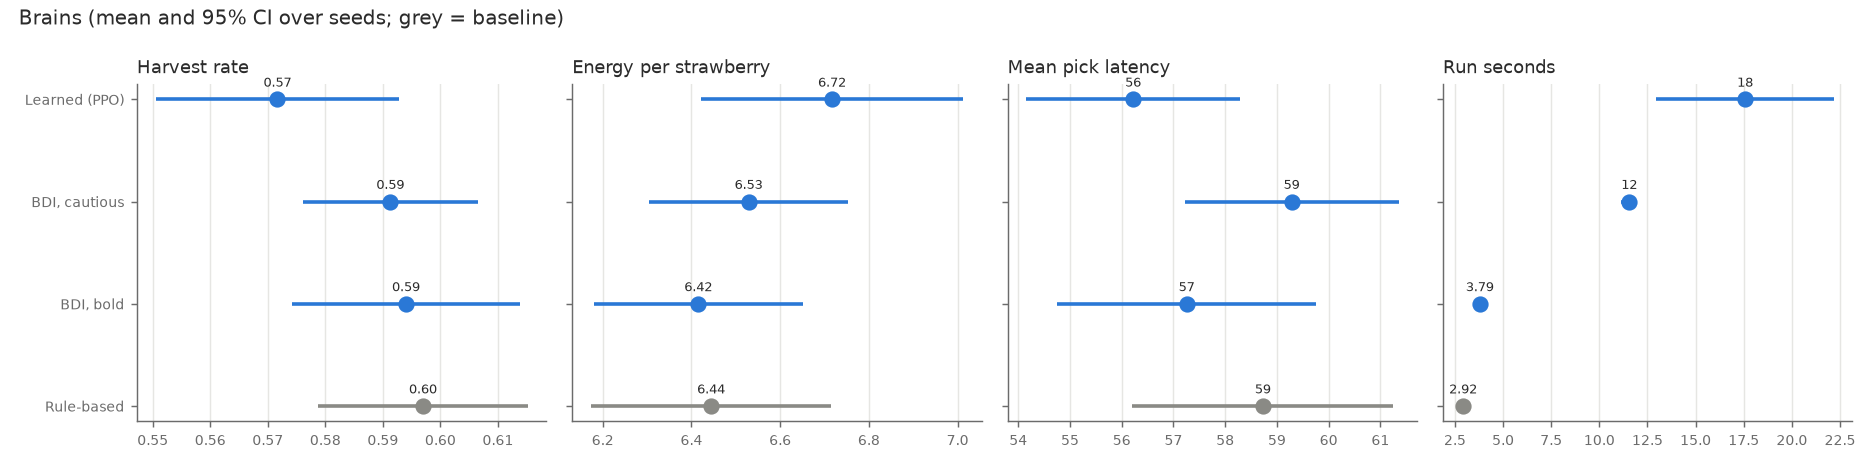

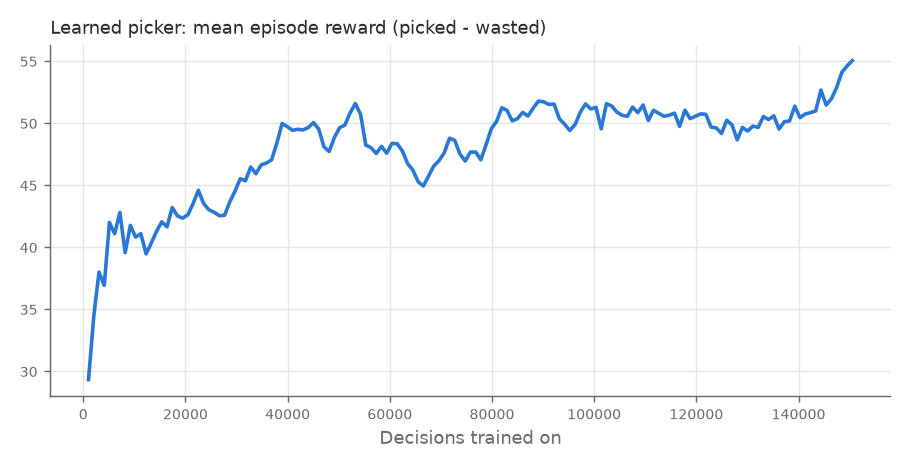

In [11]:
show("brains", ["Harvest rate", "Energy per strawberry", "Mean pick latency", "Run seconds"])
display(Image(os.path.join(ADV, "rl_training.png")))

**Reading it.** The three brains are statistically indistinguishable on harvest rate. BDI makes the
same decisions as the rules, expressed declaratively; the cautious version reconsiders constantly
and is about 4× slower to run for no gain. The learned policy ends slightly below the rules
(0.57 vs 0.60, not significant), but its training reward was **still rising** at 150k decisions
(29 → 55 per episode), so longer training might close the gap. For now the hand-written rules
are at least as good: learning pays off most when good rules are hard to write, and for this task
they were not.

### 6.6 What drives the results: Sobol sensitivity analysis

512 runs over six settings. `S1` is the share of the output's variance a setting explains on its
own; `ST` includes its interactions with the others.

Output,Energy per strawberry,Harvest rate
Parameter,,
n_pickers,0.16,0.52
n_drones,0.71,0.46
picker_capacity,0.35,0.28
initial_ripe_patches,0.11,0.16
drop_prob,0.15,0.15
strategic_bidders,0.11,0.14


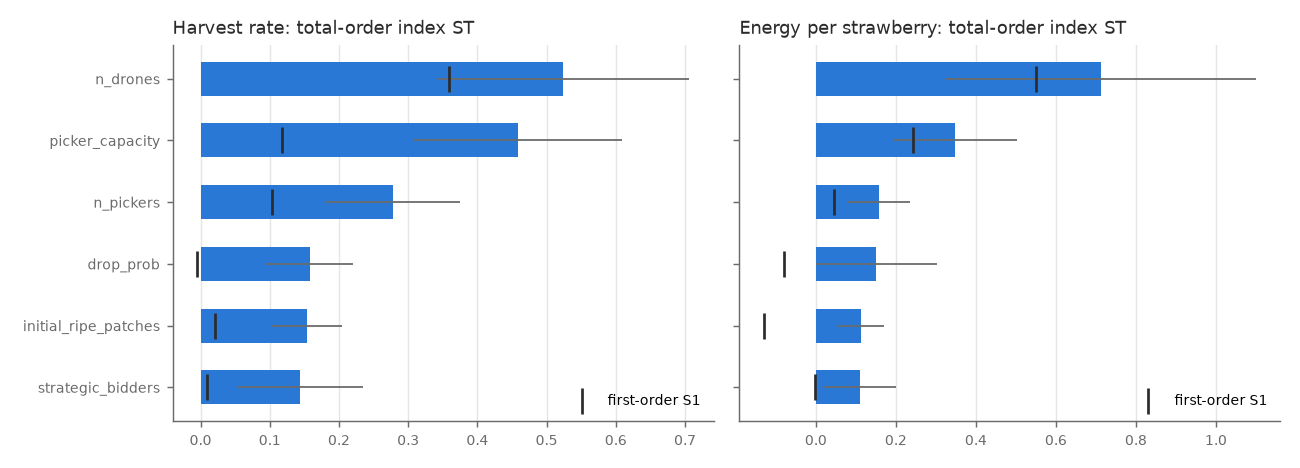

In [12]:
sobol = pd.read_csv(os.path.join(ADV, "sobol.csv"))
display(sobol.pivot(index="Parameter", columns="Output", values="ST").round(2).sort_values("Harvest rate", ascending=False))
display(Image(os.path.join(ADV, "sobol.png")))

**Reading it.** Fleet design dominates: the number of pickers explains most of the harvest-rate
variance and the number of drones most of the energy use. How robots bid (strategic bidders) and
how reliably they talk (message loss) explain little across this range. `ST` is well above `S1`
for the fleet settings, so they interact: an extra drone helps more when there are pickers free
to act on what it finds. With 64 base samples the confidence intervals are wide, so read the
ranking rather than the exact values.

### 6.7 Cheapest fleet for a target harvest: Optuna

A two-objective search (maximise harvest rate, minimise fleet cost) over fleet size, storage
capacity and allocation method. The Pareto front is the set of fleets that no other fleet beats on
both objectives at once.

,Harvest rate,Fleet cost,params_n_pickers,params_n_drones,params_picker_capacity,params_allocation
0,0.338,17.6,1,1,18,Contract Net (first-price)
1,0.338,17.6,1,1,18,Vickrey (second-price)
2,0.459,30.0,2,1,15,Combinatorial (CP-SAT)
3,0.479,42.0,2,4,15,Vickrey (second-price)
4,0.558,42.4,3,1,14,Vickrey (second-price)
5,0.595,52.0,4,1,10,Contract Net (first-price)
6,0.620,52.6,3,4,11,Vickrey (second-price)
7,0.652,55.0,3,4,15,Vickrey (second-price)
8,0.693,58.0,3,4,20,Vickrey (second-price)
9,0.720,64.0,4,2,20,Vickrey (second-price)


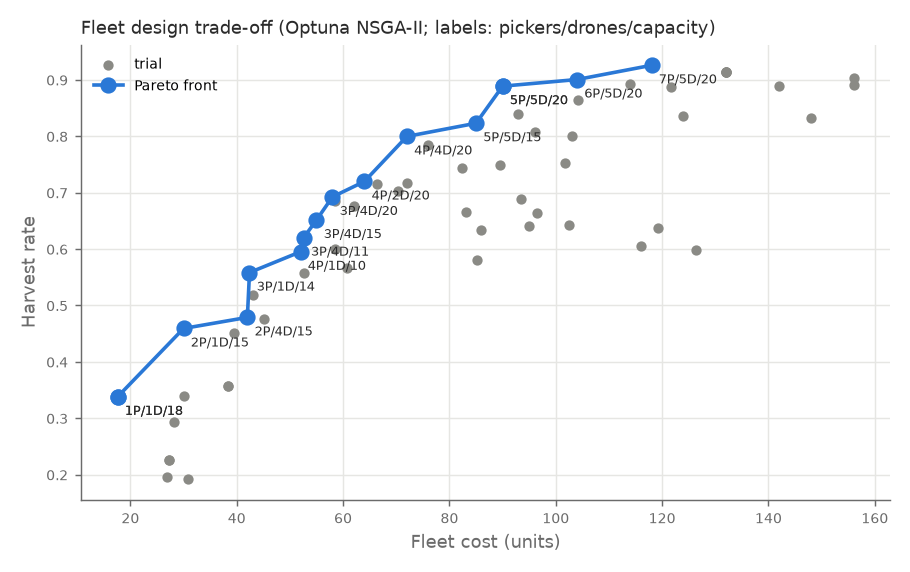

In [13]:
trials = pd.read_csv(os.path.join(ADV, "optuna_trials.csv"))
front = trials[trials["Pareto"]].sort_values("Fleet cost")
display(front[["Harvest rate", "Fleet cost", "params_n_pickers", "params_n_drones",
               "params_picker_capacity", "params_allocation"]].round(3).reset_index(drop=True))
display(Image(os.path.join(ADV, "optuna_pareto.png")))

**Reading it.** Each extra 0.1 of harvest rate costs more than the last (diminishing returns).
About 0.80 needs 4 pickers + 4 drones with capacity 20 (cost 72); about 0.90 needs 6 pickers + 5
drones (cost 104). Almost every Pareto fleet uses the Vickrey auction, though 6.1 showed Vickrey
and Contract Net allocate identically with truthful bidders, so that choice is mostly the
optimiser's tie-breaking, not evidence that Vickrey harvests more.

### 6.8 Real network (SPADE / XMPP) and a local LLM coordinator (Ollama)

5 seeds each (slow). The XMPP run sends every message as a real FIPA-style message through a local
XMPP server; the LLM run lets a local language model (`qwen2.5:3b`) allocate crop areas, with
every answer validated and a heuristic fallback when the model fails.

In [14]:
from stats_tools import compare

xmpp = pd.read_csv(os.path.join(ADV, "xmpp.csv"))
k = ["Harvest rate", "Energy per strawberry", "Messages sent", "Messages dropped", "Run seconds"]
display(xmpp.groupby("Config")[k].mean().round(3))
display(compare(xmpp, "Config", "Harvest rate", "Ideal bus").round(3))

llm_path = os.path.join(ADV, "llm.csv")
if os.path.exists(llm_path):
    llm = pd.read_csv(llm_path)
    cn = runs[(runs["Experiment"] == "allocation") & (runs["Config"] == "Contract Net")
              & (runs["Seed"].isin(llm["Seed"]))]          # the same seeds, for a fair comparison
    both = pd.concat([cn, llm])
    display(both.groupby("Config")[["Harvest rate", "Energy per strawberry", "Messages sent", "Run seconds"]].mean().round(3))
    display(compare(both, "Config", "Harvest rate", "Contract Net").round(3))
else:
    print("Run `python advanced_experiments.py llm --seeds 5` (needs Ollama) to fill this in.")

,Harvest rate,Energy per strawberry,Messages sent,Messages dropped,Run seconds
Config,,,,,
Ideal bus,0.604,5.981,881.0,0.0,2.886
SPADE / XMPP,0.637,5.750,916.0,0.0,15.049


,Config,n,mean,std,p,A12,effect,diff_lo,diff_hi,p_holm,significant
0,Ideal bus,5,0.604,0.032,NaN,NaN,NaN,NaN,NaN,NaN,False
1,SPADE / XMPP,5,0.637,0.026,0.151,0.8,large,0.0,0.064,0.151,False


,Harvest rate,Energy per strawberry,Messages sent,Run seconds
Config,,,,
Contract Net,0.604,5.981,881.0,6.649
LLM (qwen2.5:3b),0.624,5.835,172.0,251.764


,Config,n,mean,std,p,A12,effect,diff_lo,diff_hi,p_holm,significant
0,Contract Net,5,0.604,0.032,NaN,NaN,NaN,NaN,NaN,NaN,False
1,LLM (qwen2.5:3b),5,0.624,0.033,0.222,0.76,large,-0.016,0.056,0.222,False


**Reading it.** Neither difference is significant with 5 seeds, even though both effect sizes
are large (A12 ≈ 0.8). That combination means "probably a real difference, but too few runs to
be sure". 20 seeds would settle it.

* **XMPP** harvested a little more than the ideal in-memory bus (0.64 vs 0.60) and lost no
  messages, at about 5× the run time. A real network is not "better"; its timing changes the
  order in which bids arrive, so ties and close bids resolve differently. The useful result is
  that the protocol still works when messages really travel over a network.
* **The LLM coordinator** matched Contract Net (0.62 vs 0.60, not significant) and sent **5× fewer
  messages** (172 vs 881), because one prompt replaces a round of calls, bids and awards. The
  costs: each run took about **38× longer** (≈ 250 s vs 7 s; ≈ 3 s per call on this laptop's CPU),
  and validation rejected about **20 assignments per run** (unknown ids, double-booked areas or
  pickers without room). It never fell back to the heuristic, so the result is the model's own.
  The validation layer is what makes it safe to use: on average the model gave one impossible
  instruction for every four calls, and each one was caught.

**Overall.** Fleet design matters most (6.6, 6.7). Of the coordination techniques, the clear wins
are **CBS path finding**, when traffic is the bottleneck, and **Vickrey's resistance to strategic
bidding**. Several "smarter" options (Nash sectors, the central optimiser, RL, the LLM) did not
beat the simple baselines. That is a result too: the hand-designed rules and Contract Net were
already close to the best this farm allows.